# Exploratory Data Analysis and Visualization of Telco Customer Churn

**Case Study:** EDA, visualization and deep learning on a real-world dataset
**Dataset:** IBM Telco Customer Churn (Kaggle), 7,043 customers x 21 fields
**Task:** Predict whether a customer will churn (binary classification)
**Model:** Multi-Layer Perceptron (Keras)

**Notebook flow:** Step 1 Dataset selection -> Step 2 Understanding and preprocessing -> Step 3 Visualization (7 stages) -> Step 4 Model building -> Step 5 Evaluation visuals -> Step 6 Conclusion

Implementation note: preprocessing (encoding, splitting, scaling), the metrics (confusion matrix, ROC, AUC) and the feature importance are all written with explicit logic. Library functions are used only for plotting, the neural network and one cross-check.

## Step 1: Dataset Selection

- **Source:** Kaggle, "Telco Customer Churn" (IBM sample data). Same file mirrored at the IBM GitHub repository.
- **Size:** 7,043 rows, 21 fields (20 features + 1 target `Churn`), so it clears the 15-feature minimum.
- **Type:** Numerical + categorical (tabular).
- **Why this dataset:** real business problem, mixed data types, a messy numeric column (`TotalCharges`), and class imbalance, which gives real EDA and preprocessing work.

In [1]:
# ---- Imports ----
import os, re, json, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import roc_auc_score   # used ONLY to cross-check my manual AUC

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
os.makedirs('images', exist_ok=True)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

RESULTS = {}   # collects key numbers for the report

I0000 00:00:1791437881.175498     136 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791437881.215467     136 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791437882.521889     136 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Step 2: Data Understanding and Preprocessing

### 2.1 Load the data (Visualization stage 1: Acquire)

In [2]:
DATA_PATH = 'data/Telco-Customer-Churn.csv'
df = pd.read_csv(DATA_PATH)

print('Shape (rows, columns):', df.shape)
print('\nFirst 5 rows:')
df.head()

Shape (rows, columns): (7043, 21)

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# ---- Data types and basic info (Visualization stage 2: Parse) ----
print(df.dtypes)
print()
print('Unique values per column:')
print(df.nunique())

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Unique values per column:
customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies      

In [4]:
# ---- Summary statistics for numeric columns ----
df.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


### 2.2 Missing values, duplicates, data cleaning (Visualization stage 3: Filter)
`isnull()` finds no NaN, but `TotalCharges` is stored as text, which usually means hidden blank strings. Check for them.

In [5]:
print('NaN values per column:')
print(df.isnull().sum().sum(), 'total NaN')

# TotalCharges is object dtype -> look for blank strings hiding as missing values
blank_mask = df['TotalCharges'].str.strip() == ''
print('\nBlank TotalCharges rows:', blank_mask.sum())
print('Their tenure values:', df.loc[blank_mask, 'tenure'].unique())
df.loc[blank_mask, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

NaN values per column:
0 total NaN

Blank TotalCharges rows: 11
Their tenure values: [0]


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Decision:** all 11 blank rows have `tenure = 0`, meaning brand-new customers who have not been billed yet. The correct value for their total charges is **0**, not the mean or median. Imputing with the mean would invent revenue that never happened.

In [6]:
# Fix TotalCharges: blank -> '0', then convert text to float
df['TotalCharges'] = df['TotalCharges'].str.strip().replace('', '0').astype(float)
print('TotalCharges dtype now:', df['TotalCharges'].dtype)

# SeniorCitizen is 0/1 already, so it stays numeric.
# ---- Duplicates ----
print('\nFully duplicated rows (including customerID):', df.duplicated().sum())
print('customerID unique?', df['customerID'].is_unique)

# customerID is only an identifier, so it carries no predictive signal -> drop
df = df.drop(columns=['customerID'])
feature_dups = df.duplicated().sum()
print('Rows with identical feature values (different customers):', feature_dups)
RESULTS['feature_duplicates'] = int(feature_dups)

TotalCharges dtype now: float64

Fully duplicated rows (including customerID): 0
customerID unique? True
Rows with identical feature values (different customers): 22


**Decision on duplicates:** no row is duplicated as a whole record (every `customerID` is unique). 22 customers share an identical feature profile with another customer, but they are different people who happen to have the same plan, so they are legitimate observations and are **kept**.

### 2.3 Outlier detection (IQR method, manual implementation)

In [7]:
def percentile(sorted_vals, p):
    # linear interpolation percentile on a sorted array (same idea as numpy default)
    n = len(sorted_vals)
    pos = (n - 1) * p
    lo, hi = int(np.floor(pos)), int(np.ceil(pos))
    return sorted_vals[lo] + (sorted_vals[hi] - sorted_vals[lo]) * (pos - lo)

def iqr_bounds(values):
    s = np.sort(values)
    q1, q3 = percentile(s, 0.25), percentile(s, 0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
outlier_summary = {}
for col in numeric_cols:
    vals = df[col].values
    low, high = iqr_bounds(vals)
    n_out = int(((vals < low) | (vals > high)).sum())
    outlier_summary[col] = n_out
    print(f'{col:15s} lower={low:9.2f}  upper={high:9.2f}  outliers={n_out}')
RESULTS['outliers'] = outlier_summary

tenure          lower=   -60.00  upper=   124.00  outliers=0
MonthlyCharges  lower=   -46.02  upper=   171.38  outliers=0
TotalCharges    lower= -4683.52  upper=  8868.67  outliers=0


**Decision:** the IQR rule flags **0 outliers** in all three numeric columns, so no capping or removal is needed. These fields are bounded by business rules (tenure 0 to 72 months, plan prices), and long-tenure customers with high total charges are genuine, so nothing is removed.

### 2.4 Encoding categorical variables (manual)
- Binary fields (`Yes/No`, `Male/Female`) -> 0/1 through a mapping dictionary.
- `No phone service` / `No internet service` in add-on columns just means "No", so they are merged into `No` before mapping.
- Multi-class fields (`InternetService`, `Contract`, `PaymentMethod`) -> one-hot encoding written by hand, dropping the first category to avoid the dummy variable trap.

In [8]:
df_enc = df.copy()

# 1) Merge "No internet service" / "No phone service" into "No"
service_cols = ['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                'TechSupport', 'StreamingTV', 'StreamingMovies']
for col in service_cols:
    df_enc[col] = df_enc[col].replace({'No internet service': 'No', 'No phone service': 'No'})

# 2) Binary mapping
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn'] + service_cols
binary_map = {'Yes': 1, 'No': 0, 'Female': 1, 'Male': 0}   # gender: Female = 1
for col in binary_cols:
    df_enc[col] = df_enc[col].map(binary_map)

# 3) Manual one-hot encoding
def manual_one_hot(frame, col):
    categories = sorted(frame[col].unique())
    for cat in categories[1:]:                       # skip first category (reference level)
        clean = re.sub(r'[^A-Za-z0-9]+', '_', str(cat)).strip('_')
        frame[f'{col}_{clean}'] = (frame[col] == cat).astype(int)
    return frame.drop(columns=col)

for col in ['InternetService', 'Contract', 'PaymentMethod']:
    df_enc = manual_one_hot(df_enc, col)

print('Encoded shape:', df_enc.shape)
print('Any NaN left after encoding?', df_enc.isnull().sum().sum())
print('\nColumns:', list(df_enc.columns))
df_enc.head()

Encoded shape: (7043, 24)
Any NaN left after encoding? 0

Columns: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Churn', 'InternetService_Fiber_optic', 'InternetService_No', 'Contract_One_year', 'Contract_Two_year', 'PaymentMethod_Credit_card_automatic', 'PaymentMethod_Electronic_check', 'PaymentMethod_Mailed_check']


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,MonthlyCharges,TotalCharges,Churn,InternetService_Fiber_optic,InternetService_No,Contract_One_year,Contract_Two_year,PaymentMethod_Credit_card_automatic,PaymentMethod_Electronic_check,PaymentMethod_Mailed_check
0,1,0,1,0,1,0,0,0,1,0,...,29.85,29.85,0,0,0,0,0,0,1,0
1,0,0,0,0,34,1,0,1,0,1,...,56.95,1889.50,0,0,0,1,0,0,0,1
2,0,0,0,0,2,1,0,1,1,0,...,53.85,108.15,1,0,0,0,0,0,0,1
3,0,0,0,0,45,0,0,1,0,1,...,42.30,1840.75,0,0,0,1,0,0,0,0
4,1,0,0,0,2,1,0,0,0,0,...,70.70,151.65,1,1,0,0,0,0,1,0


## Step 3: Data Visualization (7 stages)

The seven stages of visualization (Ben Fry) are mapped to this notebook as follows:

| Stage | Meaning | Where it happens |
|---|---|---|
| 1. Acquire | Obtain the data | Step 2.1, CSV loaded |
| 2. Parse | Give the data structure | Step 2.1, dtypes and unique values |
| 3. Filter | Remove irrelevant or broken data | Step 2.2 and 2.3, cleaning and outlier check |
| 4. Mine | Apply statistics to find patterns | Cell below, churn rate by group |
| 5. Represent | Choose a visual form | Visuals 1 to 6 |
| 6. Refine | Improve clarity, labels, colour | Annotated and styled charts |
| 7. Interact | Let the viewer explore | Visual 7, interactive Plotly chart |

In [9]:
# ---- Stage 4: Mine ----  churn rate (%) for every categorical group
CHURN_COLOR = {0: '#4C9BE8', 1: '#E8604C'}
cat_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'InternetService', 'Contract',
            'PaymentMethod', 'PaperlessBilling', 'TechSupport', 'OnlineSecurity']

rows = []
for col in cat_cols:
    for value in sorted(df[col].unique(), key=str):
        mask = df[col] == value
        rate = (df.loc[mask, 'Churn'] == 'Yes').mean() * 100
        rows.append((col, value, int(mask.sum()), round(rate, 1)))
mine_table = pd.DataFrame(rows, columns=['feature', 'group', 'customers', 'churn_rate_%'])
mine_table.sort_values('churn_rate_%', ascending=False).head(10)

,feature,group,customers,churn_rate_%
16,PaymentMethod,Electronic check,2365,45.3
11,Contract,Month-to-month,3875,42.7
9,InternetService,Fiber optic,3096,41.9
23,OnlineSecurity,No,3498,41.8
3,SeniorCitizen,1,1142,41.7
20,TechSupport,No,3473,41.6
19,PaperlessBilling,Yes,4171,33.6
4,Partner,No,3641,33.0
6,Dependents,No,4933,31.3
0,gender,Female,3488,26.9


### Visual 1: Target class distribution

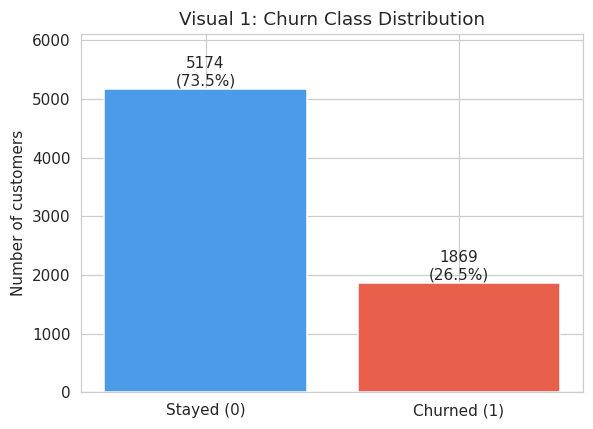

In [10]:
counts = df_enc['Churn'].value_counts().sort_index()
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(5.5, 4))
bars = ax.bar(['Stayed (0)', 'Churned (1)'], counts.values,
              color=[CHURN_COLOR[0], CHURN_COLOR[1]])
for bar, c, p in zip(bars, counts.values, pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, c + 60, f'{c}\n({p:.1f}%)', ha='center', fontsize=10)
ax.set_title('Visual 1: Churn Class Distribution')
ax.set_ylabel('Number of customers')
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout()
plt.savefig('images/01_class_distribution.png', bbox_inches='tight')
plt.show()

RESULTS['n_rows'] = int(len(df_enc))
RESULTS['churn_count'] = int(counts[1])
RESULTS['churn_pct'] = round(float(pct[1]), 2)

**What it shows:** how many customers stayed and how many left.
**Why created:** class balance decides which metrics are trustworthy. With imbalance, plain accuracy is misleading.
**Insight:** 1,869 of 7,043 customers churned (26.5%), a ratio of about 73:27. A model that always predicts "stayed" would score about 73.5% accuracy while catching no churners, so recall, F1 and AUC are reported, and class weights are used in training.

### Visual 2: Distribution of numerical features

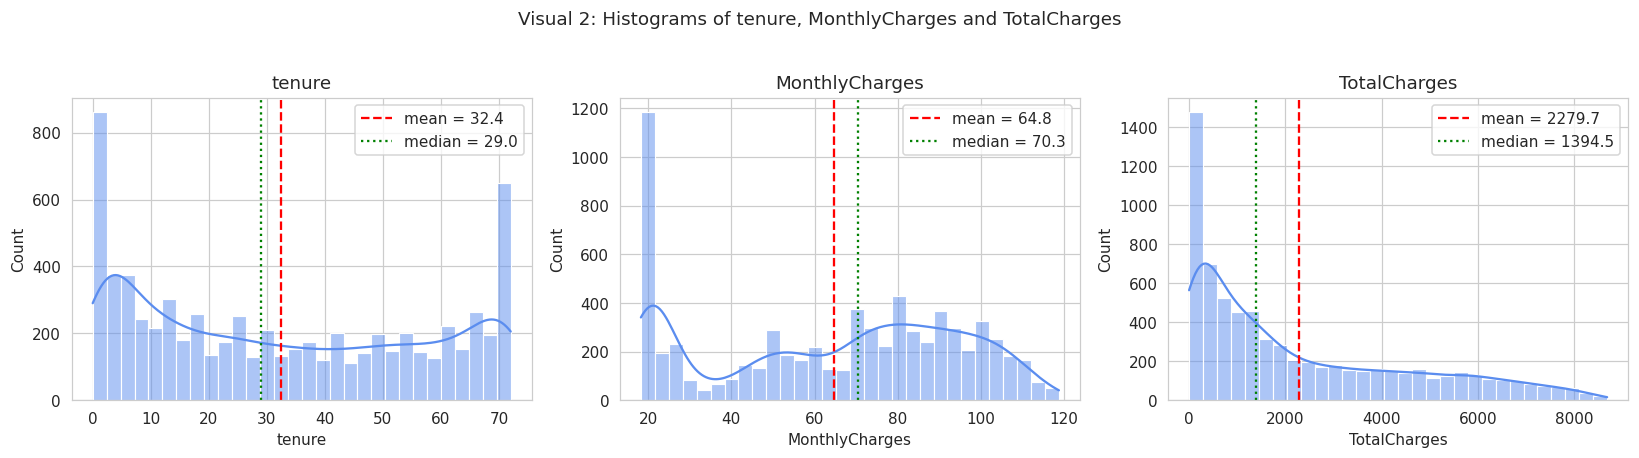

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric_cols):
    sns.histplot(df[col], bins=30, kde=True, color='#5B8DEF', ax=ax)
    ax.axvline(df[col].mean(), color='red', linestyle='--', label=f'mean = {df[col].mean():.1f}')
    ax.axvline(df[col].median(), color='green', linestyle=':', label=f'median = {df[col].median():.1f}')
    ax.set_title(col)
    ax.legend()
fig.suptitle('Visual 2: Histograms of tenure, MonthlyCharges and TotalCharges', y=1.03)
plt.tight_layout()
plt.savefig('images/02_histograms.png', bbox_inches='tight')
plt.show()

**What it shows:** the shape of each numeric feature, with mean (red) and median (green).
**Why created:** to check skewness and spot clusters before scaling.
**Insight:** `tenure` is U-shaped: 613 customers have exactly 1 month and 362 have the 72-month maximum. `MonthlyCharges` has a cluster at the cheap end (about $20, phone-only plans) and a broad hump from $70 to $100, with mean $64.76 below median $70.35. `TotalCharges` is strongly right-skewed (mean $2,280 vs median $1,395) because it is roughly tenure x monthly price, so standardization matters for the neural network.

### Visual 3: Boxplots of numeric features by churn

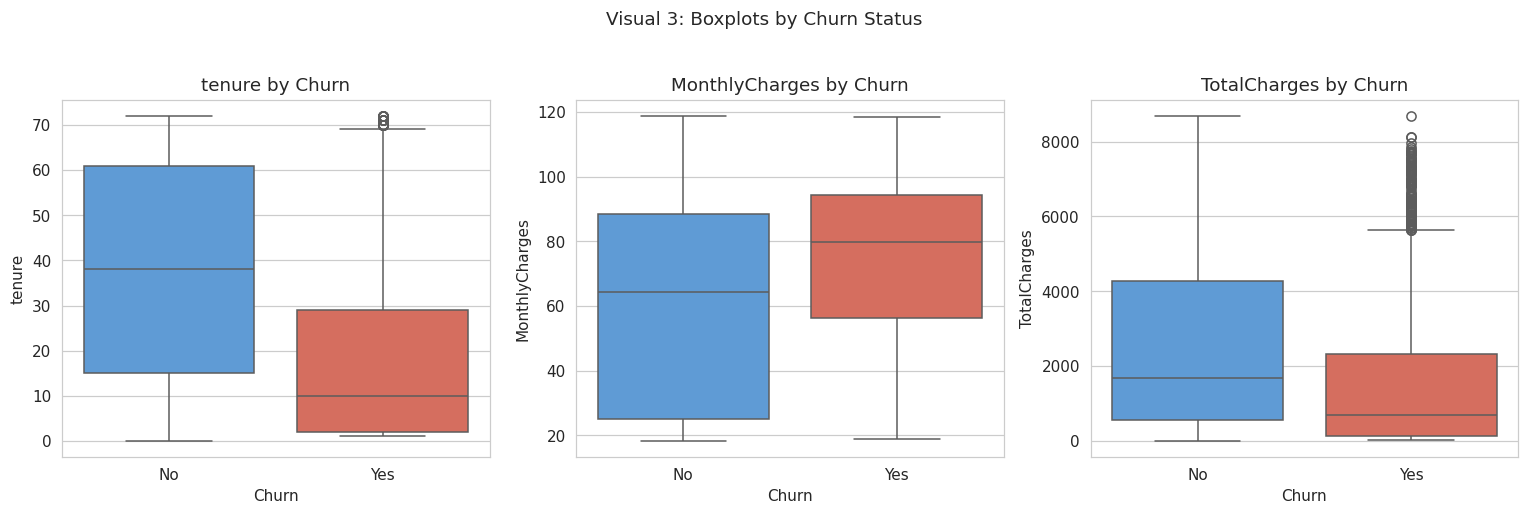

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No       38.0            64.4        1679.5
Yes      10.0            79.6         703.6


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(x='Churn', y=col, hue='Churn', data=df, palette=['#4C9BE8', '#E8604C'], legend=False, ax=ax)
    ax.set_title(f'{col} by Churn')
fig.suptitle('Visual 3: Boxplots by Churn Status', y=1.03)
plt.tight_layout()
plt.savefig('images/03_boxplots.png', bbox_inches='tight')
plt.show()

print(df.groupby('Churn')[numeric_cols].median().round(1))

**What it shows:** median, spread and outliers of each numeric feature for customers who stayed vs churned.
**Why created:** to see which numeric features separate the two classes and to confirm the outlier check visually.
**Insight:** churned customers have a far lower median tenure (10 vs 38 months) and a higher median monthly charge ($79.60 vs $64.40). Their median total charges are lower ($704 vs $1,680) simply because they stayed for less time. No extreme outliers appear, which agrees with the IQR check.

### Visual 4: Correlation heatmap

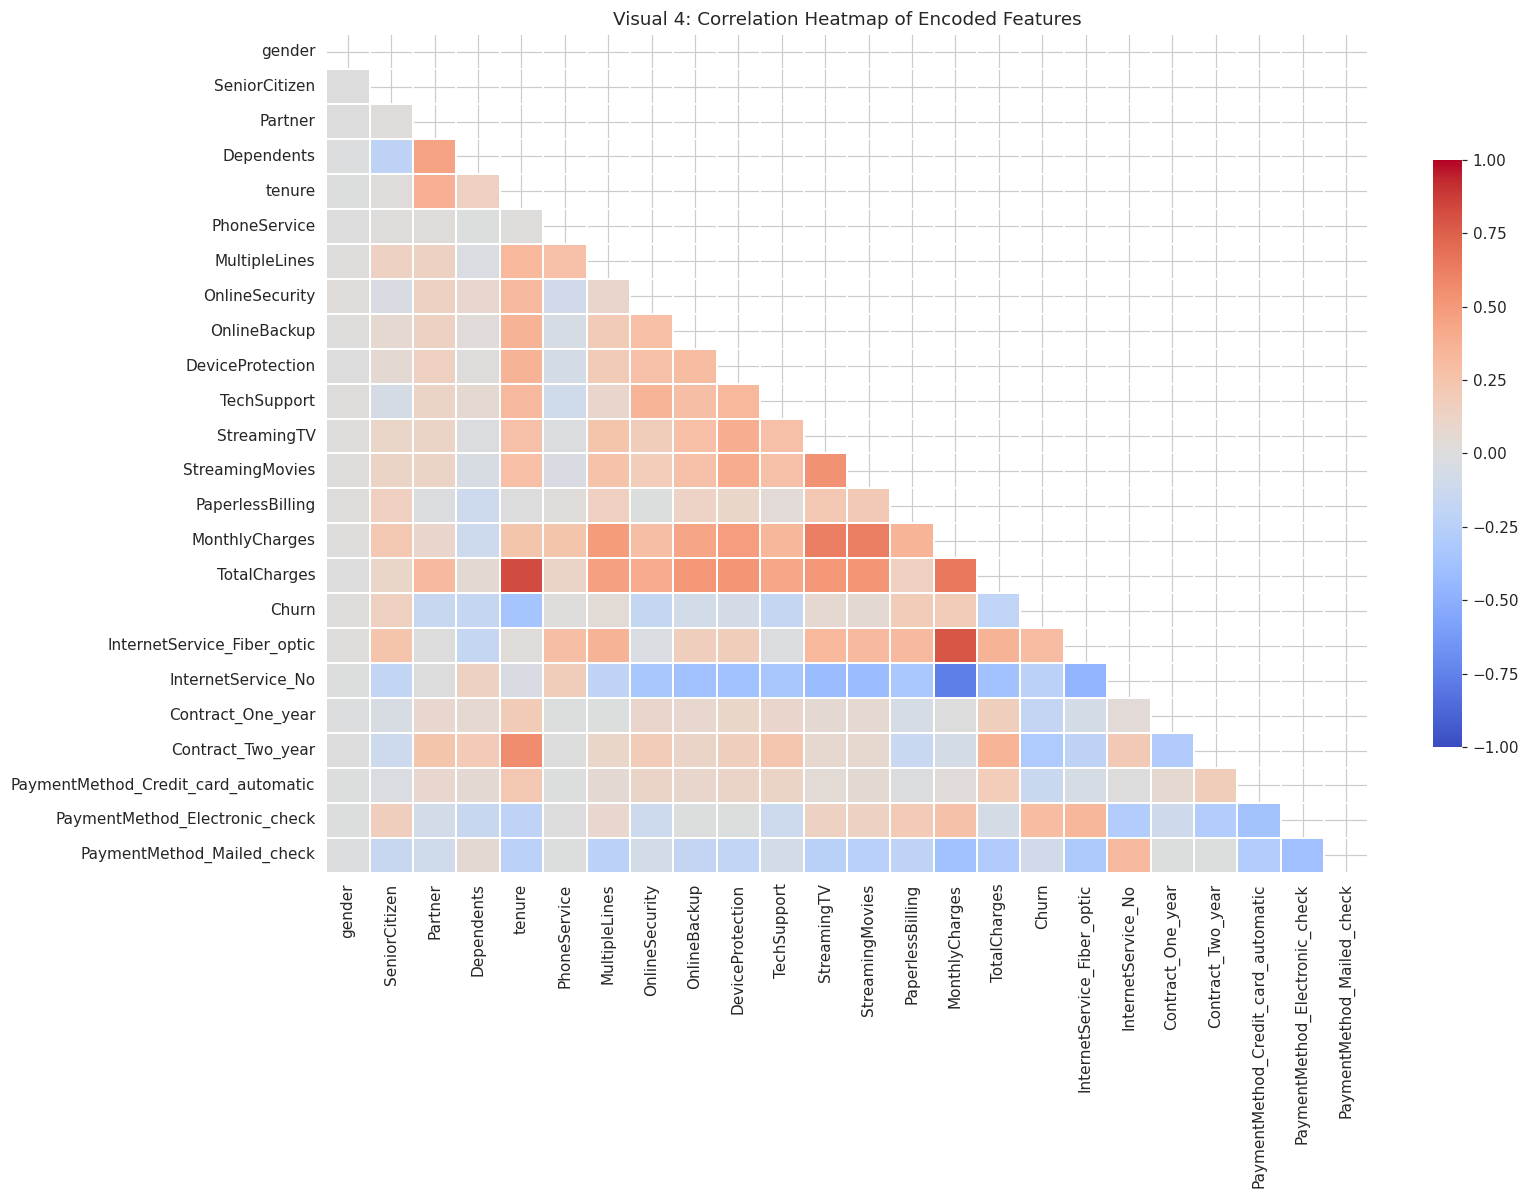

Strongest NEGATIVE correlations with Churn:
tenure               -0.352
Contract_Two_year    -0.302
InternetService_No   -0.228
TotalCharges         -0.198
Contract_One_year    -0.178
Name: Churn, dtype: float64

Strongest POSITIVE correlations with Churn:
SeniorCitizen                     0.151
PaperlessBilling                  0.192
MonthlyCharges                    0.193
PaymentMethod_Electronic_check    0.302
InternetService_Fiber_optic       0.308
Name: Churn, dtype: float64


In [13]:
corr = df_enc.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))      # hide the redundant upper triangle

plt.figure(figsize=(15, 11))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            linewidths=0.3, cbar_kws={'shrink': 0.7})
plt.title('Visual 4: Correlation Heatmap of Encoded Features')
plt.tight_layout()
plt.savefig('images/04_correlation_heatmap.png', bbox_inches='tight')
plt.show()

churn_corr = corr['Churn'].drop('Churn').sort_values()
print('Strongest NEGATIVE correlations with Churn:'); print(churn_corr.head(5).round(3))
print('\nStrongest POSITIVE correlations with Churn:'); print(churn_corr.tail(5).round(3))
RESULTS['corr_top_neg'] = {k: round(float(v), 3) for k, v in churn_corr.head(3).items()}
RESULTS['corr_top_pos'] = {k: round(float(v), 3) for k, v in churn_corr.tail(3).items()}

**What it shows:** pairwise linear correlation between all encoded features (red positive, blue negative).
**Why created:** to find features related to churn and to detect redundant (multicollinear) features.
**Insight:** the strongest negative correlations with churn are `tenure` (-0.352), the two-year contract (-0.302) and having no internet service (-0.228). The strongest positive ones are fiber optic internet (+0.308), electronic check payment (+0.302) and `MonthlyCharges` (+0.193). Month-to-month is the reference level of `Contract`, so its effect shows up as the mirror image of the two contract columns. `tenure` and `TotalCharges` are highly correlated (0.826), so the two carry overlapping information; a neural network tolerates this, but a linear model would need care.

### Visual 5: Churn rate by key categorical drivers

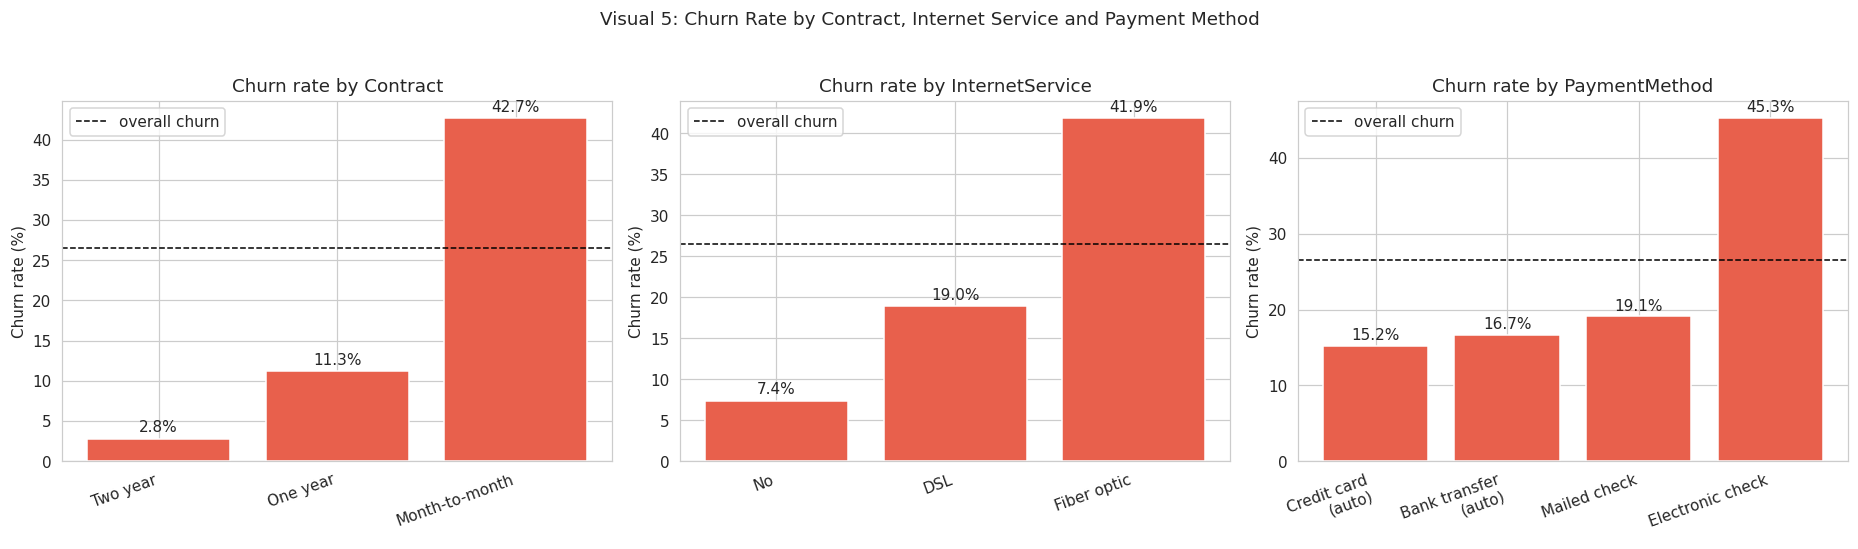

In [14]:
drivers = ['Contract', 'InternetService', 'PaymentMethod']
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, col in zip(axes, drivers):
    rate = df.groupby(col)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).sort_values()
    bars = ax.bar(range(len(rate)), rate.values, color='#E8604C')
    ax.set_xticks(range(len(rate)))
    ax.set_xticklabels([lbl.replace(' (automatic)', '\n(auto)') for lbl in rate.index],
                       rotation=20, ha='right')
    for b, v in zip(bars, rate.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f'{v:.1f}%', ha='center')
    ax.axhline(RESULTS['churn_pct'], color='black', linestyle='--', linewidth=1, label='overall churn')
    ax.set_title(f'Churn rate by {col}')
    ax.set_ylabel('Churn rate (%)')
    ax.legend()
fig.suptitle('Visual 5: Churn Rate by Contract, Internet Service and Payment Method', y=1.03)
plt.tight_layout()
plt.savefig('images/05_churn_by_category.png', bbox_inches='tight')
plt.show()

**What it shows:** the percentage of customers who churned inside each category, against the overall rate (dashed line).
**Why created:** the heatmap only shows linear relationships on 0/1 columns. Group churn rates are easier to read and easier to act on.
**Insight:** month-to-month contracts churn at 42.7%, versus 11.3% for one-year and 2.8% for two-year contracts. Fiber optic customers churn at 41.9% against 19.0% for DSL. Electronic check payers churn at 45.3%, compared with 15.2% to 19.1% for the other three payment methods. Long contracts and automatic payment look like the strongest retention levers.

### Visual 6: Tenure vs Monthly Charges scatter plot

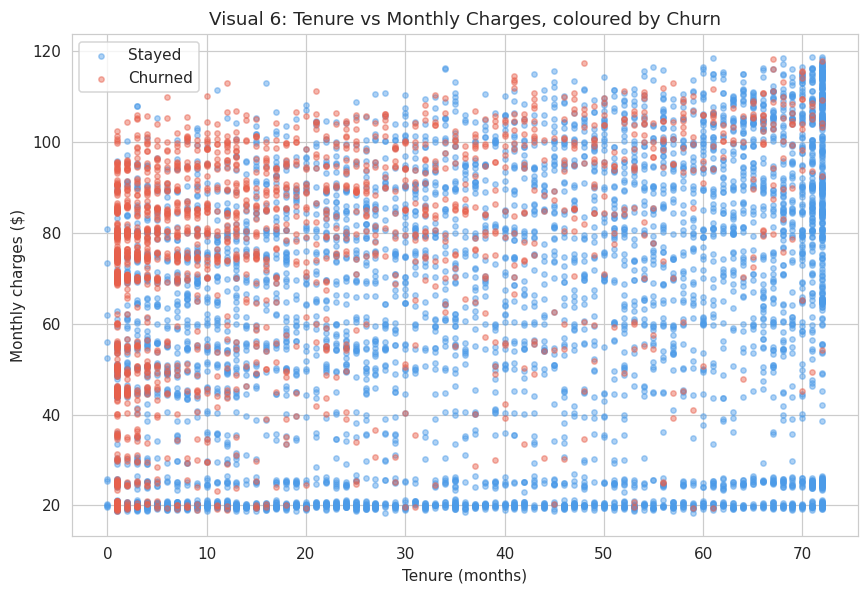

In [15]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for label, name in [(0, 'Stayed'), (1, 'Churned')]:
    sub = df_enc[df_enc['Churn'] == label]
    ax.scatter(sub['tenure'], sub['MonthlyCharges'], s=12, alpha=0.45,
               color=CHURN_COLOR[label], label=name)
ax.set_xlabel('Tenure (months)')
ax.set_ylabel('Monthly charges ($)')
ax.set_title('Visual 6: Tenure vs Monthly Charges, coloured by Churn')
ax.legend()
plt.tight_layout()
plt.savefig('images/06_scatter_tenure_charges.png', bbox_inches='tight')
plt.show()

**What it shows:** every customer as a point, positioned by tenure and monthly price, coloured by outcome.
**Why created:** to see how two important numeric features jointly separate churners.
**Insight:** churn (red) concentrates in the top-left corner: short tenure with high monthly charges. Among the 880 customers with tenure of 12 months or less and monthly charges of $70 or more, 68.1% churned, against 26.5% overall. Long-tenure customers are mostly blue regardless of price.

### Visual 7: Interactive chart (Visualization stage 7: Interact)
Hover for exact values, click legend items to hide a class, drag to zoom. The chart is also saved as a standalone HTML file in `images/`.

In [16]:
fig_int = px.scatter(
    df, x='tenure', y='MonthlyCharges', color='Churn',
    color_discrete_map={'No': '#4C9BE8', 'Yes': '#E8604C'},
    hover_data=['Contract', 'InternetService', 'PaymentMethod', 'TotalCharges'],
    opacity=0.55, title='Visual 7: Interactive Tenure vs Monthly Charges (hover, zoom, filter)'
)
fig_int.update_layout(width=850, height=520)
fig_int.write_html('images/07_interactive_tenure_charges.html')
fig_int.show()

**What it shows:** the same relationship as Visual 6, but explorable.
**Why created:** to complete the Interact stage. An analyst can isolate one group, zoom into a dense region and read each customer's contract, internet service and payment method in the tooltip.
**Insight:** hovering over the top-left red cluster confirms what Visual 5 suggested. Of the 599 churners in the segment (tenure of 12 months or less, monthly charges of $70 or more), 99.3% are on month-to-month contracts, 98.0% have fiber optic internet and 69.1% pay by electronic check.

### 2.5 Train / validation / test split (manual, stratified 70 / 15 / 15)
Stratified means each split keeps the same churn percentage as the full data. The scaler is fitted on the training set only, to avoid data leakage.

In [17]:
y_all = df_enc['Churn'].values
X_all = df_enc.drop(columns='Churn')
feature_names = list(X_all.columns)

def stratified_split(y, ratios=(0.70, 0.15, 0.15), seed=42):
    rng = np.random.RandomState(seed)
    train_idx, val_idx, test_idx = [], [], []
    for cls in np.unique(y):                        # split each class separately
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)
        n = len(idx)
        n_train = int(n * ratios[0])
        n_val = int(n * ratios[1])
        train_idx += list(idx[:n_train])
        val_idx += list(idx[n_train:n_train + n_val])
        test_idx += list(idx[n_train + n_val:])
    for lst in (train_idx, val_idx, test_idx):      # mix classes inside each split
        rng.shuffle(lst)
    return np.array(train_idx), np.array(val_idx), np.array(test_idx)

tr, va, te = stratified_split(y_all)
X_train, X_val, X_test = X_all.iloc[tr].copy(), X_all.iloc[va].copy(), X_all.iloc[te].copy()
y_train, y_val, y_test = y_all[tr], y_all[va], y_all[te]

for name, yy in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]:
    print(f'{name:11s} n={len(yy):5d}  churn rate={yy.mean() * 100:.2f}%')
RESULTS['split'] = {'train': int(len(tr)), 'val': int(len(va)), 'test': int(len(te))}

Train       n= 4929  churn rate=26.54%
Validation  n= 1056  churn rate=26.52%
Test        n= 1058  churn rate=26.56%


In [18]:
# ---- Manual z-score standardization: z = (x - mean) / std, fitted on TRAIN only ----
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
mu = X_train[num_cols].mean()
sigma = np.sqrt(((X_train[num_cols] - mu) ** 2).mean())      # population std

for frame in (X_train, X_val, X_test):
    frame[num_cols] = (frame[num_cols] - mu) / sigma

print('Train means after scaling (should be ~0):', X_train[num_cols].mean().round(4).values)
print('Train stds after scaling  (should be ~1):', X_train[num_cols].std().round(4).values)

# convert to float32 numpy arrays for Keras
Xtr, Xva, Xte = [f.values.astype('float32') for f in (X_train, X_val, X_test)]
print('\nInput dimension (number of features):', Xtr.shape[1])
RESULTS['n_features_model'] = int(Xtr.shape[1])

Train means after scaling (should be ~0): [ 0. -0. -0.]
Train stds after scaling  (should be ~1): [1.0001 1.0001 1.0001]

Input dimension (number of features): 23


## Step 4: Model Building (MLP)

**Why an MLP:** the data is tabular, with 23 numeric/binary inputs after encoding. A fully connected network is the standard deep learning baseline for this kind of data.

**Architecture:** Input (23) -> Dense(h1, ReLU) -> Dropout(0.3) -> Dense(h2, ReLU) -> Dropout(0.3) -> Dense(1, Sigmoid)

**Loss:** binary cross-entropy. **Optimizer:** Adam. **Imbalance handling:** class weights, computed by hand as `n_samples / (2 x n_class)`.

In [19]:
# ---- Manual metric functions (no sklearn shortcuts) ----
def confusion_counts(y_true, y_pred):
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    return tn, fp, fn, tp

def classification_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_counts(y_true, y_pred)
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return dict(accuracy=accuracy, precision=precision, recall=recall, f1=f1)

def manual_roc(y_true, y_score):
    # sort by score high -> low; each step lowers the threshold past one more sample
    order = np.argsort(-y_score)
    y_sorted = y_true[order]
    tps = np.cumsum(y_sorted)                 # true positives at each threshold
    fps = np.cumsum(1 - y_sorted)             # false positives at each threshold
    tpr = np.concatenate([[0.0], tps / tps[-1]])
    fpr = np.concatenate([[0.0], fps / fps[-1]])
    auc = np.sum((fpr[1:] - fpr[:-1]) * (tpr[1:] + tpr[:-1]) / 2)   # trapezoid rule
    return fpr, tpr, float(auc)

# ---- Class weights ----
n = len(y_train)
class_weight = {0: n / (2 * (y_train == 0).sum()), 1: n / (2 * (y_train == 1).sum())}
print('Class weights:', {k: round(float(v), 3) for k, v in class_weight.items()})

Class weights: {0: 0.681, 1: 1.884}


In [20]:
def build_mlp(input_dim, units, lr, dropout=0.3):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(units[0], activation='relu'),
        layers.Dropout(dropout),
        layers.Dense(units[1], activation='relu'),
        layers.Dropout(dropout),
        layers.Dense(1, activation='sigmoid'),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

build_mlp(Xtr.shape[1], (64, 32), 0.001).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,649 (14.25 KB)

 Trainable params: 3,649 (14.25 KB)

 Non-trainable params: 0 (0.00 B)

### 4.1 Basic hyperparameter tuning (grid search on the validation set)
Grid: learning rate {0.001, 0.01} x hidden units {(32,16), (64,32)} x batch size {32, 64} = 8 combinations. Each is trained with early stopping, and the best one is chosen by **validation AUC**. The test set is not touched during tuning.

In [21]:
grid = list(itertools.product([0.001, 0.01], [(32, 16), (64, 32)], [32, 64]))
tuning_rows = []

for lr, units, batch in grid:
    tf.keras.utils.set_random_seed(SEED)                       # same start for a fair comparison
    model = build_mlp(Xtr.shape[1], units, lr)
    stopper = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    hist = model.fit(Xtr, y_train, validation_data=(Xva, y_val), epochs=40, batch_size=batch,
                     class_weight=class_weight, callbacks=[stopper], verbose=0)
    val_scores = model.predict(Xva, verbose=0).ravel()
    _, _, val_auc = manual_roc(y_val, val_scores)
    tuning_rows.append({'learning_rate': lr, 'units': str(units), 'batch_size': batch,
                        'epochs_run': len(hist.history['loss']), 'val_auc': round(val_auc, 4)})
    print(f'lr={lr:<6} units={str(units):9s} batch={batch:<3} epochs={len(hist.history["loss"]):2d}  val AUC={val_auc:.4f}')

tuning_df = pd.DataFrame(tuning_rows).sort_values('val_auc', ascending=False).reset_index(drop=True)
best = tuning_df.iloc[0]
BEST_LR, BEST_UNITS, BEST_BATCH = float(best['learning_rate']), eval(best['units']), int(best['batch_size'])
print('\nBest configuration:', BEST_LR, BEST_UNITS, BEST_BATCH)
RESULTS['tuning'] = tuning_df.to_dict(orient='records')
RESULTS['best_config'] = {'learning_rate': BEST_LR, 'units': list(BEST_UNITS), 'batch_size': BEST_BATCH}
tuning_df

lr=0.001  units=(32, 16)  batch=32  epochs=15  val AUC=0.8417


lr=0.001  units=(32, 16)  batch=64  epochs=14  val AUC=0.8405


lr=0.001  units=(64, 32)  batch=32  epochs=12  val AUC=0.8417


lr=0.001  units=(64, 32)  batch=64  epochs=16  val AUC=0.8398


lr=0.01   units=(32, 16)  batch=32  epochs=14  val AUC=0.8374


lr=0.01   units=(32, 16)  batch=64  epochs=13  val AUC=0.8424


lr=0.01   units=(64, 32)  batch=32  epochs=11  val AUC=0.8403


lr=0.01   units=(64, 32)  batch=64  epochs= 6  val AUC=0.8364

Best configuration: 0.01 (32, 16) 64


,learning_rate,units,batch_size,epochs_run,val_auc
0,0.010,"(32, 16)",64,13,0.8424
1,0.001,"(32, 16)",32,15,0.8417
2,0.001,"(64, 32)",32,12,0.8417
3,0.001,"(32, 16)",64,14,0.8405
4,0.010,"(64, 32)",32,11,0.8403
5,0.001,"(64, 32)",64,16,0.8398
6,0.010,"(32, 16)",32,14,0.8374
7,0.010,"(64, 32)",64,6,0.8364


### 4.2 Final training with the best configuration

In [22]:
tf.keras.utils.set_random_seed(SEED)
final_model = build_mlp(Xtr.shape[1], BEST_UNITS, BEST_LR)
stopper = keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
history = final_model.fit(Xtr, y_train, validation_data=(Xva, y_val), epochs=100,
                          batch_size=BEST_BATCH, class_weight=class_weight,
                          callbacks=[stopper], verbose=0)
epochs_run = len(history.history['loss'])
print('Training stopped after', epochs_run, 'epochs (early stopping on validation loss)')
print('Final train loss: %.4f | val loss: %.4f' % (history.history['loss'][-1], history.history['val_loss'][-1]))
RESULTS['epochs_run'] = epochs_run
RESULTS['total_params'] = int(final_model.count_params())

Training stopped after 16 epochs (early stopping on validation loss)
Final train loss: 0.4851 | val loss: 0.4858


## Step 5: Model Evaluation Visualization

### Chart 1 and 2: Loss vs Epoch and Accuracy vs Epoch

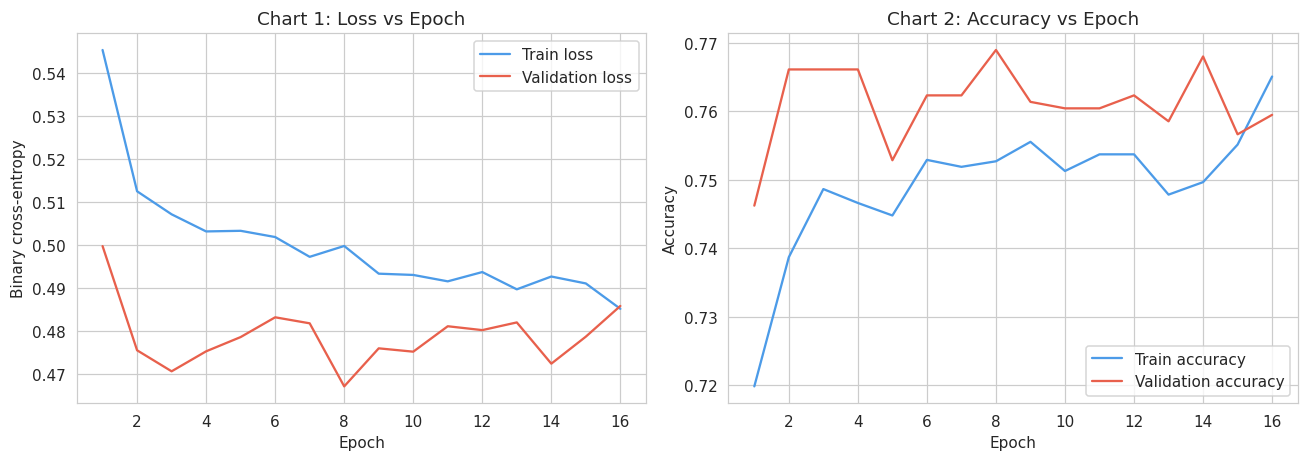

In [23]:
h = history.history
ep = range(1, epochs_run + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

axes[0].plot(ep, h['loss'], label='Train loss', color='#4C9BE8')
axes[0].plot(ep, h['val_loss'], label='Validation loss', color='#E8604C')
axes[0].set_title('Chart 1: Loss vs Epoch')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Binary cross-entropy'); axes[0].legend()

axes[1].plot(ep, h['accuracy'], label='Train accuracy', color='#4C9BE8')
axes[1].plot(ep, h['val_accuracy'], label='Validation accuracy', color='#E8604C')
axes[1].set_title('Chart 2: Accuracy vs Epoch')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].legend()

plt.tight_layout()
plt.savefig('images/08_loss_accuracy_curves.png', bbox_inches='tight')
plt.show()

**What it shows:** training and validation loss (left) and accuracy (right) after each epoch.
**Why created:** to check that the network is learning and to detect overfitting.
**Interpretation:** training loss falls from 0.545 to 0.485 and the validation loss stays between 0.467 and 0.50, so there is no growing gap between the two curves, which means no overfitting. Validation sits slightly *below* training because dropout is switched off when validating, and the training loss is class-weighted while the validation loss is not. The lowest validation loss came at epoch 8 (about 0.467). Early stopping with patience 8 then ended training at epoch 16 and restored the epoch-8 weights. Validation accuracy stays in a narrow band of about 75% to 77%, which suggests that the main signals are learned early and extra epochs add little.

### Chart 3: Confusion matrix (test set)

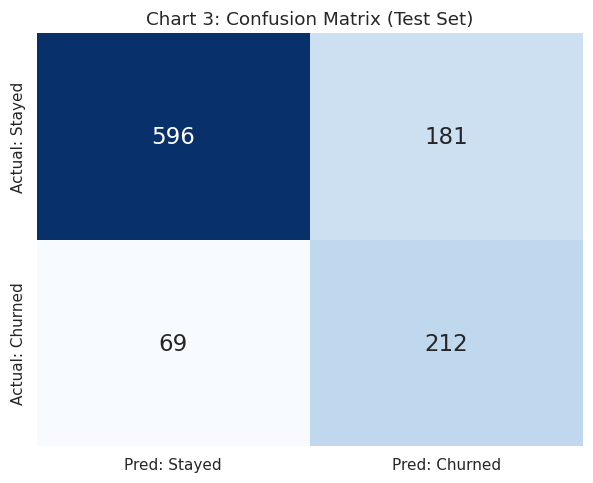

TN=596  FP=181  FN=69  TP=212
accuracy  : 0.7637
precision : 0.5394
recall    : 0.7544
f1        : 0.6291


In [24]:
test_scores = final_model.predict(Xte, verbose=0).ravel()
test_pred = (test_scores >= 0.5).astype(int)

tn, fp, fn, tp = confusion_counts(y_test, test_pred)
cm = np.array([[tn, fp], [fn, tp]])
metrics = classification_metrics(y_test, test_pred)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, annot_kws={'size': 15},
            xticklabels=['Pred: Stayed', 'Pred: Churned'],
            yticklabels=['Actual: Stayed', 'Actual: Churned'], ax=ax)
ax.set_title('Chart 3: Confusion Matrix (Test Set)')
plt.tight_layout()
plt.savefig('images/09_confusion_matrix.png', bbox_inches='tight')
plt.show()

print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')
for k, v in metrics.items():
    print(f'{k:10s}: {v:.4f}')
RESULTS['confusion'] = {'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp}
RESULTS['test_metrics'] = {k: round(float(v), 4) for k, v in metrics.items()}

**What it shows:** on the 1058 test customers, how many predictions were right and wrong for each class.
**Why created:** accuracy alone hides which type of error the model makes.
**Interpretation:** the model correctly identified **212** of the 281 customers who really churned (recall 75.4%) and correctly kept **596** of the 777 loyal customers. It missed 69 churners (false negatives) and wrongly flagged 181 loyal customers (false positives). Precision is 53.9%, so a bit under half the customers flagged are false alarms. Overall accuracy is 76.4% and F1 is 0.629. This trade-off was chosen on purpose: class weights push the model toward catching churners, because missing a churner (losing the customer) usually costs more than sending a retention offer to a customer who would have stayed.

### Chart 4: ROC curve and AUC (test set)

AUC (manual trapezoid) = 0.8470 | AUC (sklearn cross-check) = 0.8470


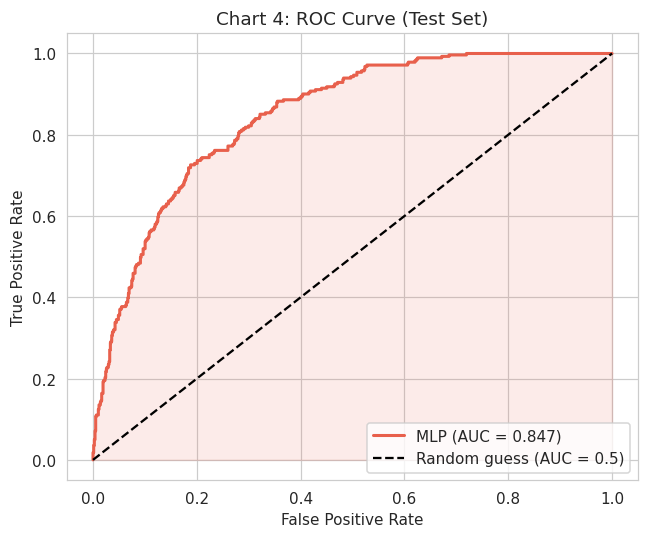

In [25]:
fpr, tpr, auc_manual = manual_roc(y_test, test_scores)
auc_check = roc_auc_score(y_test, test_scores)        # cross-check only
print(f'AUC (manual trapezoid) = {auc_manual:.4f} | AUC (sklearn cross-check) = {auc_check:.4f}')

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='#E8604C', linewidth=2, label=f'MLP (AUC = {auc_manual:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess (AUC = 0.5)')
plt.fill_between(fpr, tpr, alpha=0.12, color='#E8604C')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('Chart 4: ROC Curve (Test Set)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('images/10_roc_curve.png', bbox_inches='tight')
plt.show()

RESULTS['auc_manual'] = round(auc_manual, 4)
RESULTS['auc_sklearn'] = round(float(auc_check), 4)

**What it shows:** the true positive rate against the false positive rate as the decision threshold changes from strict to lenient.
**Why created:** AUC measures how well the model ranks churners above non-churners, independent of any single threshold, which is what matters with imbalanced data.
**Interpretation:** the AUC is **0.847** (the manual trapezoid calculation and the scikit-learn cross-check agree). A random guess scores 0.5 and a perfect model 1.0, so the model has good discrimination: a randomly chosen churner gets a higher churn probability than a randomly chosen loyal customer about 85% of the time. The test AUC (0.847) is close to the validation AUC (0.842), which confirms the model generalizes and that tuning did not overfit the validation set.

### Chart 5: Predicted probability distribution (error analysis)
For a classification task this plays the role of the error distribution chart: it shows where the model is confident and where classes overlap.

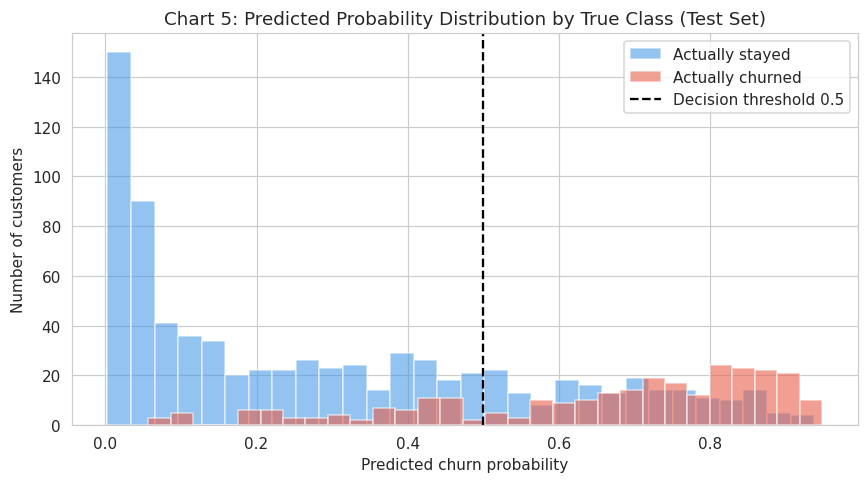

In [26]:
plt.figure(figsize=(8, 4.5))
plt.hist(test_scores[y_test == 0], bins=30, alpha=0.6, color=CHURN_COLOR[0], label='Actually stayed')
plt.hist(test_scores[y_test == 1], bins=30, alpha=0.6, color=CHURN_COLOR[1], label='Actually churned')
plt.axvline(0.5, color='black', linestyle='--', label='Decision threshold 0.5')
plt.xlabel('Predicted churn probability'); plt.ylabel('Number of customers')
plt.title('Chart 5: Predicted Probability Distribution by True Class (Test Set)')
plt.legend()
plt.tight_layout()
plt.savefig('images/11_probability_distribution.png', bbox_inches='tight')
plt.show()

**What it shows:** the histogram of predicted churn probability, split by what customers actually did.
**Why created:** for classification the "error distribution" is the overlap between the two classes. This chart shows where the mistakes come from.
**Interpretation:** loyal customers (blue) pile up at very low probabilities (the tallest bars are below 0.1), while churners (red) concentrate between 0.7 and 0.95. The errors are the red bars left of the 0.5 line (missed churners) and the blue bars right of it (false alarms). The two classes overlap mostly between 0.4 and 0.8, which is where the model is genuinely unsure, and suggests that those customers look alike in the available fields. Moving the threshold would trade recall for precision, and the business cost of each error should decide where it sits.

### Feature analysis: permutation importance (manual)
Idea: shuffle one feature column in the validation set, so its link to the target is broken, and measure how much the AUC drops. A bigger drop means the model relies on that feature more. Averaged over 5 shuffles per feature.

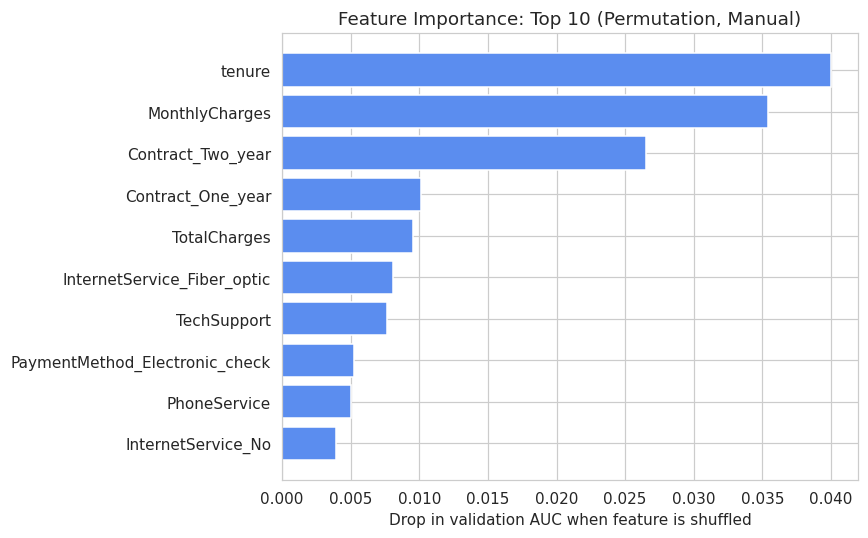

Baseline validation AUC: 0.8424
tenure                            0.0400
MonthlyCharges                    0.0354
Contract_Two_year                 0.0266
Contract_One_year                 0.0102
TotalCharges                      0.0095
InternetService_Fiber_optic       0.0081
TechSupport                       0.0077
PaymentMethod_Electronic_check    0.0052
PhoneService                      0.0050
InternetService_No                0.0039
dtype: float64


In [27]:
rng = np.random.RandomState(SEED)
_, _, base_auc = manual_roc(y_val, final_model.predict(Xva, verbose=0).ravel())

importance = {}
for j, name in enumerate(feature_names):
    drops = []
    for _ in range(5):
        X_shuffled = Xva.copy()
        X_shuffled[:, j] = rng.permutation(X_shuffled[:, j])          # break this feature only
        _, _, auc_s = manual_roc(y_val, final_model.predict(X_shuffled, verbose=0).ravel())
        drops.append(base_auc - auc_s)
    importance[name] = float(np.mean(drops))

imp = pd.Series(importance).sort_values(ascending=False)
top = imp.head(10)[::-1]

plt.figure(figsize=(8, 5))
plt.barh(top.index, top.values, color='#5B8DEF')
plt.xlabel('Drop in validation AUC when feature is shuffled')
plt.title('Feature Importance: Top 10 (Permutation, Manual)')
plt.tight_layout()
plt.savefig('images/12_feature_importance.png', bbox_inches='tight')
plt.show()

print('Baseline validation AUC:', round(base_auc, 4))
print(imp.head(10).round(4))
RESULTS['top_features'] = {k: round(float(v), 4) for k, v in imp.head(8).items()}

**What it shows:** how much the validation AUC falls when one feature is randomly shuffled.
**Why created:** to explain what the network relies on, since a neural network is not directly interpretable.
**Interpretation:** the most important features are `tenure` (AUC drop 0.040), `MonthlyCharges` (0.035) and the two-year contract flag (0.027), followed by the one-year contract, `TotalCharges`, fiber optic internet and tech support. This agrees with the EDA: tenure, price and contract length were the strongest signals in the heatmap and the churn-rate charts. Demographic fields such as gender barely matter. Because `tenure` and `TotalCharges` are correlated, their importance is partly shared, so the individual numbers should be read as approximate.

In [28]:
# ---- Save all collected numbers for the report ----
with open('results.json', 'w') as f:
    json.dump(RESULTS, f, indent=2)
print(json.dumps(RESULTS, indent=2)[:1500])

{
  "feature_duplicates": 22,
  "outliers": {
    "tenure": 0,
    "MonthlyCharges": 0,
    "TotalCharges": 0
  },
  "n_rows": 7043,
  "churn_count": 1869,
  "churn_pct": 26.54,
  "corr_top_neg": {
    "tenure": -0.352,
    "Contract_Two_year": -0.302,
    "InternetService_No": -0.228
  },
  "corr_top_pos": {
    "MonthlyCharges": 0.193,
    "PaymentMethod_Electronic_check": 0.302,
    "InternetService_Fiber_optic": 0.308
  },
  "split": {
    "train": 4929,
    "val": 1056,
    "test": 1058
  },
  "n_features_model": 23,
  "tuning": [
    {
      "learning_rate": 0.01,
      "units": "(32, 16)",
      "batch_size": 64,
      "epochs_run": 13,
      "val_auc": 0.8424
    },
    {
      "learning_rate": 0.001,
      "units": "(32, 16)",
      "batch_size": 32,
      "epochs_run": 15,
      "val_auc": 0.8417
    },
    {
      "learning_rate": 0.001,
      "units": "(64, 32)",
      "batch_size": 32,
      "epochs_run": 12,
      "val_auc": 0.8417
    },
    {
      "learning_rate": 0.00

## Step 6: Conclusion and Future Scope

### What was learned from the dataset
- 26.5% of the 7,043 customers churned, so the data is imbalanced and accuracy alone is not a good metric.
- The data needed little cleaning, but `TotalCharges` hid 11 blank values, all for customers with tenure 0. They were set to 0 rather than imputed.
- The strongest churn patterns are short tenure, month-to-month contracts (42.7% churn vs 2.8% for two-year), fiber optic internet (41.9%), electronic check payment (45.3%) and higher monthly prices. The segment with tenure of 12 months or less and monthly charges of $70 or more churned at 68.1%.

### How the model performed
- MLP (23 inputs, 32 -> 16 -> 1, 1313 parameters), best settings from the grid: learning rate 0.01, batch size 64.
- Test results: accuracy 76.4%, recall 75.4%, precision 53.9%, F1 0.629, AUC 0.847.
- No sign of overfitting (train and validation curves stay close, test AUC matches validation AUC). Permutation importance confirms the model uses the same drivers the EDA found.

### Challenges
- Class imbalance: handled with class weights, at the price of lower precision.
- Hidden missing values stored as blank text.
- Correlated features (`tenure`, `TotalCharges`) make importance scores approximate.
- Small differences between tuning runs (validation AUC 0.836 to 0.842) are within random noise, so the "best" configuration is only slightly better than the others.

### Future scope
- Try a gradient boosting model (XGBoost or LightGBM) as a comparison. On tabular data of this size it often matches or beats an MLP.
- Handle imbalance with SMOTE or focal loss and compare against class weights.
- Tune the decision threshold using real retention-offer cost against customer lifetime value.
- Use SHAP for per-customer explanations that a retention team could act on.
- Use cross-validation and a wider search (Optuna or random search) for more reliable tuning.
- Add richer data: support call logs, usage trends, billing history and time series of plan changes.